# Splatfacto v2 — better 3D Gaussian Splatting for `binh_gom_1`
Run this **after** your existing Splatfacto notebook has prepared the data (`/kaggle/working/ceramic_vases_1` with `transforms.json` and `images_2`) and Nerfstudio is installed (same Kaggle session, GPU on). Your old run is **not** modified: this writes a new experiment `ceramic_splatfacto_v2`.

**What is different from the previous run (5,000 iters, random init, PSNR 20.37):**
1. Start the Gaussians from the dataset's reference OBJ surface instead of 10,000 random points (the biggest expected quality gain).
2. Train 15,000 iterations instead of 5,000.
3. Turn on scale regularisation, which suppresses the long needle-shaped Gaussians.
4. Export in the standard Gaussian-splat format (no `--ply-color-mode rgb`).

Every cell prints what it did. If a check fails, stop and send me the message — do not skip it.

In [18]:
from pathlib import Path
DATA_DIR = Path("/kaggle/working/ceramic_vases_1")
print("DATA_DIR exists:", DATA_DIR.exists())
print("transforms.json:", (DATA_DIR / "transforms.json").is_file())
print("images_2 count :", len(list((DATA_DIR / "images_2").glob("*.png"))) if (DATA_DIR / "images_2").exists() else 0)
print("OBJ in working :", list(DATA_DIR.glob("*.obj")))
print("OBJ in input   :", [str(p) for p in Path("/kaggle/input").rglob("ceramic_vases_1.obj")])

DATA_DIR exists: True
transforms.json: True
images_2 count : 180
OBJ in working : [PosixPath('/kaggle/working/ceramic_vases_1/ceramic_vases_1.obj')]
OBJ in input   : ['/kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/ceramic_vases_1/ceramic_vases_1/ceramic_vases_1.obj']


In [19]:
import shutil
src = next(Path("/kaggle/input").rglob("ceramic_vases_1.obj"))
shutil.copy2(src, DATA_DIR / src.name)
print("Copied:", src)

Copied: /kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/ceramic_vases_1/ceramic_vases_1/ceramic_vases_1.obj


In [20]:
import importlib.util, torch
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - turn on a GPU in Notebook Settings")
print("nerfstudio installed:", importlib.util.find_spec("nerfstudio") is not None)

GPU: True Tesla T4
nerfstudio installed: True


In [ ]:
!pip install nerfstudio==1.1.5

In [21]:
import json, re, shutil
import numpy as np
from pathlib import Path
from PIL import Image

INPUT_ROOT = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working/ceramic_vases_1")

# --- find source folder
def valid(p):
    return p.is_dir() and (p/"metadata.json").is_file() and (p/"images").is_dir() and len(list((p/"images").glob("*.png"))) > 0
cands = [m.parent for m in INPUT_ROOT.rglob("metadata.json") if valid(m.parent)]
cands.sort(key=lambda p: (p.name != "ceramic_vases_1", len(list((p/"images").glob("*.png"))) != 180, len(p.parts)))
assert cands, "Attach the LR3D-CULT2 dataset with Add Input"
SOURCE_DIR = cands[0]; print("Source:", SOURCE_DIR)

# --- copy images, metadata, OBJ
(WORK_DIR/"images").mkdir(parents=True, exist_ok=True)
srcs = sorted((SOURCE_DIR/"images").glob("*.png")); assert len(srcs) == 180, len(srcs)
for s in srcs:
    d = WORK_DIR/"images"/s.name
    if not d.exists() or d.stat().st_size != s.stat().st_size: shutil.copy2(s, d)
for pat in ("metadata.json", "*.obj", "*.mtl", "*.jpeg", "*.jpg"):
    for s in ([SOURCE_DIR/pat] if pat == "metadata.json" else SOURCE_DIR.glob(pat)):
        if s.is_file(): shutil.copy2(s, WORK_DIR/s.name)
print("images:", len(list((WORK_DIR/"images").glob("*.png"))), "| OBJ:", [p.name for p in WORK_DIR.glob("*.obj")])

# --- transforms.json (same look-at construction as your original notebook)
metadata = json.load(open(WORK_DIR/"metadata.json", encoding="utf-8"))
W = H = 512; FL = 711.1235633043419; CX = CY = 256.0
def c2w(pos):
    cp = np.array([pos["x"], pos["y"], pos["z"]], float)
    fwd = -cp / np.linalg.norm(cp)
    up = np.array([0., 1., 0.]); right = np.cross(fwd, up)
    if np.linalg.norm(right) < 1e-8:
        up = np.array([0., 0., 1.]); right = np.cross(fwd, up)
    right /= np.linalg.norm(right); up = np.cross(right, fwd)
    m = np.eye(4); m[:3, :3] = np.column_stack((right, up, -fwd)); m[:3, 3] = cp
    return m.tolist()

names = {p.name for p in (WORK_DIR/"images").glob("*.png")}; frames_out = []
for cam in ("CAM1", "CAM2"):
    fs = [f for f in metadata["frames"] if str(f.get("camera", "")).split("|")[-1] == cam]
    fs = sorted(fs, key=lambda f: f.get("frame", -1))[:90]; assert len(fs) == 90, (cam, len(fs))
    for f in fs:
        n = int(f["frame"]) + 1
        m = [x for x in names if cam in x and re.search(rf"\.{n:04d}\.png$", x)]
        assert m, f"missing image {cam} {n:04d}"
        frames_out.append({"file_path": "./images/" + sorted(m)[0], "transform_matrix": c2w(f["position_world"])})
assert len(frames_out) == 180
json.dump({"camera_model": "OPENCV", "fl_x": FL, "fl_y": FL, "cx": CX, "cy": CY, "w": W, "h": H, "frames": frames_out},
          open(WORK_DIR/"transforms.json", "w"), indent=2)
print("transforms.json frames:", len(frames_out))

# --- 256x256 images
(WORK_DIR/"images_2").mkdir(exist_ok=True)
for s in sorted((WORK_DIR/"images").glob("*.png")):
    d = WORK_DIR/"images_2"/s.name
    if not d.exists(): Image.open(s).convert("RGB").resize((256, 256), Image.Resampling.LANCZOS).save(d)
print("images_2:", len(list((WORK_DIR/"images_2").glob("*.png"))))

Source: /kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/ceramic_vases_1/ceramic_vases_1
images: 180 | OBJ: ['ceramic_vases_1.obj']
transforms.json frames: 180
images_2: 180


In [22]:
print((WORK_DIR/"transforms.json").is_file(), len(list((WORK_DIR/"images_2").glob("*.png"))), [p.name for p in WORK_DIR.glob("*.obj")])

True 180 ['ceramic_vases_1.obj']


OBJ vertices: (53300, 3) min [-2.478 -3.247 -2.152] max [2.478 3.247 2.152]
camera distance from origin: 17.00 .. 18.10
object radius: 3.81 | object centre: [ 0.014  0.359 -0.084]


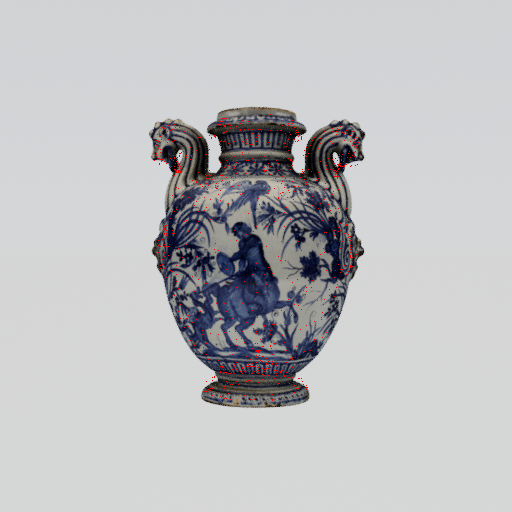

Red dots must sit ON the vase. If they are shifted, mirrored or off to one side, STOP and send me this image.


In [23]:
# 1) Build an initial point cloud from the OBJ and CHECK it lines up with the cameras
import json, numpy as np
from pathlib import Path
DATA_DIR = Path("/kaggle/working/ceramic_vases_1")
obj = next(DATA_DIR.glob("*.obj"))
V = []
with open(obj) as f:
    for line in f:
        if line.startswith("v "):
            p = line.split(); V.append([float(p[1]), float(p[2]), float(p[3])])
V = np.array(V); print("OBJ vertices:", V.shape, "min", V.min(0).round(3), "max", V.max(0).round(3))

tf = json.load(open(DATA_DIR / "transforms.json"))
cams = np.array([np.array(fr["transform_matrix"])[:3, 3] for fr in tf["frames"]])
print("camera distance from origin: %.2f .. %.2f" % (np.linalg.norm(cams, axis=1).min(), np.linalg.norm(cams, axis=1).max()))
print("object radius: %.2f" % np.linalg.norm(V - V.mean(0), axis=1).max(), "| object centre:", V.mean(0).round(3))

# project onto training image 0 and save an overlay to eyeball the alignment
from PIL import Image, ImageDraw
fr = tf["frames"][0]; c2w = np.array(fr["transform_matrix"]); w2c = np.linalg.inv(c2w)
pc = (w2c @ np.c_[V, np.ones(len(V))].T).T[:, :3]
front = pc[:, 2] < 0                                  # OpenGL convention: camera looks down -z
u = tf["fl_x"] * pc[front, 0] / -pc[front, 2] + tf["cx"]
v = -tf["fl_y"] * pc[front, 1] / -pc[front, 2] + tf["cy"]
img = Image.open(DATA_DIR / fr["file_path"].replace("./", "")).convert("RGB"); d = ImageDraw.Draw(img)
for x, y in zip(u[::40], v[::40]): d.point((float(x), float(y)), fill=(255, 0, 0))
img.save("/kaggle/working/init_alignment_check.png"); display(img)
print("Red dots must sit ON the vase. If they are shifted, mirrored or off to one side, STOP and send me this image.")

In [24]:
# 2) Write the init point cloud (grey colour) and point transforms.json at it. Original is backed up.
rng = np.random.default_rng(0)
idx = rng.choice(len(V), size=min(100_000, len(V)), replace=False)
P = V[idx].astype("<f4"); col = np.full((len(P), 3), 190, dtype="u1")
rec = np.empty(len(P), dtype=[("p", "<f4", 3), ("c", "u1", 3)]); rec["p"] = P; rec["c"] = col
hdr = ("ply\nformat binary_little_endian 1.0\nelement vertex %d\nproperty float x\nproperty float y\nproperty float z\n"
       "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n" % len(P))
(DATA_DIR / "init_points.ply").write_bytes(hdr.encode() + rec.tobytes())

import shutil
if not (DATA_DIR / "transforms_original.json").exists():
    shutil.copy2(DATA_DIR / "transforms.json", DATA_DIR / "transforms_original.json")
tf["ply_file_path"] = "init_points.ply"
json.dump(tf, open(DATA_DIR / "transforms.json", "w"), indent=2)
print("Init points:", len(P), "| transforms.json now has ply_file_path =", tf["ply_file_path"])

Init points: 53300 | transforms.json now has ply_file_path = init_points.ply


In [25]:
# 3) Trainer configuration (new experiment, old run untouched)
import copy, time
from nerfstudio.configs.method_configs import method_configs
cfg = copy.deepcopy(method_configs["splatfacto"])
OUTPUT_DIR = Path("/kaggle/working/nerfstudio_outputs")
cfg.method_name = "splatfacto"; cfg.experiment_name = "ceramic_splatfacto_v2"
cfg.timestamp = time.strftime("%Y-%m-%d_%H%M%S"); cfg.output_dir = OUTPUT_DIR
cfg.max_num_iterations = 15000
cfg.steps_per_save = 2500; cfg.steps_per_eval_batch = 0
cfg.vis = "tensorboard"
dm = cfg.pipeline.datamanager
dm.dataparser.data = DATA_DIR; dm.dataparser.downscale_factor = 2; dm.dataparser.load_3D_points = True
dm.cache_images = "cpu"; dm.cache_images_type = "uint8"
m = cfg.pipeline.model
m.random_init = False                  # use the OBJ points
m.use_scale_regularization = True      # fewer needle gaussians
m.stop_split_at = 10000
cfg.save_config()
dm.dataparser.eval_mode = "fraction"; dm.dataparser.train_split_fraction = 0.9   # same 162 / 18 split as before
dm.images_on_gpu = False; dm.masks_on_gpu = False; dm.max_thread_workers = 2
m.sh_degree = 3; m.background_color = "black"
cfg.optimizers["means"]["scheduler"].max_steps = cfg.max_num_iterations           # LR schedule must end at 15,000, not 30,000
RUN_DIR = OUTPUT_DIR / cfg.experiment_name / "splatfacto" / cfg.timestamp
print("Run folder:", RUN_DIR, "| iterations:", cfg.max_num_iterations)

[18:05:13] Saving config to:                                                                    ]8;id=518533;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/configs/experiment_config.py\experiment_config.py]8;;\:]8;id=784222;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/configs/experiment_config.py#136\136]8;;\
           /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_v2/splatfacto/2026-11-14_18051                         
           3/config.yml                                                                                                 

Run folder: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_v2/splatfacto/2026-11-14_180513 | iterations: 15000


In [27]:
# 4) Train
from nerfstudio.engine.trainer import Trainer
trainer = Trainer(config=cfg, local_rank=0, world_size=1)
trainer.setup(test_mode="val")
print("Gaussians at start:", trainer.pipeline.model.means.shape[0], "(old run started from 10,000 random points)")
t0 = time.time(); trainer.train()
print("Finished in %.1f min" % ((time.time() - t0) / 60))

/usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py:137: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.grad_scaler = GradScaler(enabled=self.use_grad_scaler)


[18:05:55] Saving checkpoints to:                                                                         ]8;id=821721;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py\trainer.py]8;;\:]8;id=566119;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py#142\142]8;;\
           /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_v2/splatfacto/2026-11-14_180513/nerfstud               
           io_models                                                                                                    

No Nerfstudio checkpoint to load, so training from scratch.

logging events to: /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_v2/splatfacto/2026-11-14_180513

Gaussians at start: 53300 (old run started from 10,000 random points)


[18:05:56] Caching / undistorting train images                                            ]8;id=800486;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py\full_images_datamanager.py]8;;\:]8;id=344434;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py#230\230]8;;\

... (48 outputs left out)

Output()

Step (% Done)       Train Iter (time)    ETA (time)           Train Rays / Sec     Test Rays / Sec       
-------------------------------------------------------------------------------------------------------- 
13910 (92.73%)      15.852 ms            17 s, 279.029 ms     4.26 M                                     
13920 (92.80%)      15.867 ms            17 s, 136.367 ms     4.26 M                                     
13930 (92.87%)      15.128 ms            16 s, 186.927 ms     4.34 M                                     
13940 (92.93%)      15.005 ms            15 s, 905.557 ms     4.37 M                                     
13950 (93.00%)      14.859 ms            15 s, 601.934 ms     4.41 M                                     
13960 (93.07%)      14.855 ms            15 s, 449.625 ms     4.42 M                                     
13970 (93.13%)      14.855 ms            15 s, 300.494 ms     4.42 M                                     
13980 (93.20%)      14.938 ms            15 s,

╭────────────────────────────────────────────── 🎉 Training Finished 🎉 ───────────────────────────────────────────────╮
│                        ╷                                                                                             │
│   Config File          │ /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_v2/splatfacto/2026-11-14_180513/co…   │
│   Checkpoint Directory │ /kaggle/working/nerfstudio_outputs/ceramic_splatfacto_v2/splatfacto/2026-11-14_180513/ne…   │
│                        ╵                                                                                             │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Finished in 22.3 min


In [28]:
# 5) Evaluate on the same 18 held-out views (compare with the old PSNR 20.37 / SSIM 0.827 / LPIPS 0.291)
import sys, torch
def trusted_torch_load(*a, **k):
    k.setdefault("weights_only", False); return torch.serialization.load(*a, **k)
torch.load = trusted_torch_load
sys.argv = ["ns-eval", "--load-config", str(RUN_DIR / "config.yml"),
            "--output-path", "/kaggle/working/splatfacto_v2_evaluation.json",
            "--render-output-path", "/kaggle/working/splatfacto_v2_eval_renders"]
from nerfstudio.scripts.eval import entrypoint as eval_entry
eval_entry()
print(json.dumps(json.load(open("/kaggle/working/splatfacto_v2_evaluation.json"))["results"], indent=2))

Loading latest checkpoint from load_dir

✅ Done loading checkpoint from 
/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_v2/splatfacto/2026-11-14_180513/nerfstudio_models/step-000014999.c
kpt

[18:28:38] Caching / undistorting eval images                                             ]8;id=927722;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py\full_images_datamanager.py]8;;\:]8;id=645462;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py#230\230]8;;\

Output()

Output()

Saved results to: /kaggle/working/splatfacto_v2_evaluation.json

{
  "psnr": 24.675140380859375,
  "psnr_std": 7.347367286682129,
  "ssim": 0.934920072555542,
  "ssim_std": 0.06921999156475067,
  "lpips": 0.10668223351240158,
  "lpips_std": 0.12507067620754242,
  "num_rays_per_sec": 1499554.125,
  "num_rays_per_sec_std": 105766.5546875,
  "fps": 22.881380081176758,
  "fps_std": 1.613869547843933
}


In [29]:
# 6) Export in the standard Gaussian-splat format
import numpy as np
try: np_scalar = np._core.multiarray.scalar
except AttributeError: np_scalar = np.core.multiarray.scalar
torch.serialization.add_safe_globals([np_scalar])
sys.argv = ["ns-export", "gaussian-splat", "--load-config", str(RUN_DIR / "config.yml"),
            "--output-dir", "/kaggle/working/3D_Viewer_Exports", "--output-filename", "ceramic_splatfacto_v2.ply"]
from nerfstudio.scripts.exporter import entrypoint as export_entry
export_entry()

Loading latest checkpoint from load_dir

✅ Done loading checkpoint from 
/kaggle/working/nerfstudio_outputs/ceramic_splatfacto_v2/splatfacto/2026-11-14_180513/nerfstudio_models/step-000014999.c
kpt

3209 NaN/Inf elements in scale_0

-3209 Gaussians have NaN/Inf and 487 have low opacity, only export 218537/222233

In [ ]:
# 7) Clean for the web viewer: drop faint, oversized and far-away Gaussians; drop view-dependent SH to keep the file small
KEEP_SH = False
src = Path("/kaggle/working/3D_Viewer_Exports/ceramic_splatfacto_v2.ply"); raw = src.read_bytes()
h = raw.index(b"end_header\n") + 11
lines = raw[:h].decode().splitlines()
names = [l.split()[2] for l in lines if l.startswith("property")]
n = int([l.split()[2] for l in lines if l.startswith("element vertex")][0])
assert all(l.split()[1] == "float" for l in lines if l.startswith("property")), "unexpected non-float property"
A = np.frombuffer(raw[h:], dtype="<f4").reshape(n, len(names)); col = {k: i for i, k in enumerate(names)}
op = 1 / (1 + np.exp(-A[:, col["opacity"]]))
sc = np.exp(A[:, [col["scale_0"], col["scale_1"], col["scale_2"]]]).max(1)
xyz = A[:, [col["x"], col["y"], col["z"]]]; lo, hi = np.percentile(xyz, [2, 98], axis=0); pad = (hi - lo) * 0.15
keep = (op > 0.3) & (sc < np.percentile(sc, 99)) & np.all((xyz > lo - pad) & (xyz < hi + pad), axis=1)
use = [k for k in names if k not in ("nx", "ny", "nz") and (KEEP_SH or not k.startswith("f_rest"))]
out = A[keep][:, [col[k] for k in use]].astype("<f4")
hdr = "ply\nformat binary_little_endian 1.0\nelement vertex %d\n" % len(out) + "".join("property float %s\n" % k for k in use) + "end_header\n"
dst = Path("/kaggle/working/3D_Viewer_Exports/ceramic_splatfacto_vase.ply"); dst.write_bytes(hdr.encode() + out.tobytes())
print("kept %d of %d Gaussians | %.1f MB -> %s" % (len(out), n, dst.stat().st_size / 1e6, dst))
print("Download this file, put it in your viewer folder (it replaces the old ceramic_splatfacto_clean.ply) and hard-refresh the page.")

**Retraining Nerfacto**

In [8]:
from pathlib import Path
print([str(p) for p in Path("/kaggle/input").rglob("Nerfacto_backup.zip")])
print([str(p) for p in Path("/kaggle/input").rglob("config.yml")])

[]
['/kaggle/input/datasets/dhyani1611/nerfacto-backup-zip/config.yml']


In [9]:
import re, shutil
from pathlib import Path

SRC = Path("/kaggle/input/datasets/dhyani1611/nerfacto-backup-zip")
cfg_text = (SRC / "config.yml").read_text()
ts   = re.search(r"^timestamp:\s*(\S+)", cfg_text, re.M).group(1)
exp  = re.search(r"^experiment_name:\s*(\S+)", cfg_text, re.M).group(1)
print("timestamp:", ts, "| experiment:", exp)

RUN = Path("/kaggle/working/nerfstudio_outputs") / exp / "nerfacto" / ts
shutil.copytree(SRC, RUN, dirs_exist_ok=True)
print("config:", (RUN / "config.yml").exists())
print("checkpoints:", list((RUN / "nerfstudio_models").glob("*.ckpt")))

timestamp: 2026-11-14_055958 | experiment: ceramic_vases_1
config: True
checkpoints: [PosixPath('/kaggle/working/nerfstudio_outputs/ceramic_vases_1/nerfacto/2026-11-14_055958/nerfstudio_models/step-000004999.ckpt')]


In [14]:
import sys, subprocess
r = subprocess.run([sys.executable, "-m", "pip", "install", "nerfstudio==1.1.5"], text=True)
print("install return code:", r.returncode)

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
INFO: pip is looking at multiple versions of nuscenes-devkit to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of tensorboard to determine which versio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.85.1 requires protobuf<8.0.0,>=7.35.1, but you have protobuf 3.20.3 which is incompatible.
kaggle-environments 1.33.3 requires protobuf>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
onnx 1.23.2 requires protobuf>=6.31.1, but you have protobuf 3.20.3 which is incompatible.
google-cloud-texttospeech 2.38.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
a2a-sdk 1.3.0 requires protobuf>=5.29.5, but you have protobuf 3.20.3 which is incompatible.
google-cloud-vision 3.16.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
google-cloud-videointelligence 2.21.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
grpc-google-iam-v1 0.14.6 requires protobuf<8.0.0,>=6.33.5, but you have 

install return code: 0


In [30]:
metadata = json.load(open(WORK_DIR / "metadata.json"))
FL = 711.1235633043419

def c2w(pos):
    cp = np.array([pos["x"], pos["y"], pos["z"]], dtype=float)
    fwd = -cp / np.linalg.norm(cp)
    up = np.array([0.0, 1.0, 0.0])
    right = np.cross(fwd, up)
    right = right / np.linalg.norm(right)
    up = np.cross(right, fwd)
    m = np.eye(4)
    m[:3, :3] = np.column_stack((right, up, -fwd))
    m[:3, 3] = cp
    return m.tolist()

names = [p.name for p in (WORK_DIR / "images").glob("*.png")]
frames_out = []
for cam in ["CAM1", "CAM2"]:
    fs = [f for f in metadata["frames"] if str(f.get("camera", "")).split("|")[-1] == cam]
    fs = sorted(fs, key=lambda f: f.get("frame", -1))[:90]
    for f in fs:
        n = int(f["frame"]) + 1
        suffix = ".%04d.png" % n
        match = [x for x in names if cam in x and x.endswith(suffix)]
        frames_out.append({"file_path": "./images/" + sorted(match)[0],
                           "transform_matrix": c2w(f["position_world"])})

out = {"camera_model": "OPENCV", "fl_x": FL, "fl_y": FL, "cx": 256.0, "cy": 256.0,
       "w": 512, "h": 512, "frames": frames_out}
json.dump(out, open(WORK_DIR / "transforms.json", "w"), indent=2)
print("frames:", len(frames_out))

frames: 180


In [31]:
(WORK_DIR / "images_2").mkdir(exist_ok=True)
for s in sorted((WORK_DIR / "images").glob("*.png")):
    d = WORK_DIR / "images_2" / s.name
    if not d.exists():
        img = Image.open(s).convert("RGB").resize((256, 256), Image.Resampling.LANCZOS)
        img.save(d)
n_small = len(list((WORK_DIR / "images_2").glob("*.png")))
print("images_2:", n_small)

images_2: 180


In [32]:
print((WORK_DIR / "transforms.json").is_file(),
      len(list((WORK_DIR / "images").glob("*.png"))),
      len(list((WORK_DIR / "images_2").glob("*.png"))))

True 180 180


In [35]:
import os, sys, subprocess
fix = """
import torch, numpy as np
from numpy._core.multiarray import scalar
torch.serialization.add_safe_globals([scalar, np.dtype, type(np.dtype(np.float32)), np.dtypes.Float64DType])
from nerfstudio.scripts.exporter import entrypoint
entrypoint()
"""
env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"] = "0"
cmd = [sys.executable, "-c", fix, "pointcloud", "--load-config", str(RUN / "config.yml"),
       "--output-dir", "/kaggle/working/nerf_export", "--num-points", "1000000",
       "--remove-outliers", "True", "--normal-method", "open3d",
       "--obb-center", "0", "0", "0",
       "--obb-rotation", "0", "0", "0",
       "--obb-scale", "1.2", "1.2", "1.2"]
result = subprocess.run(cmd, env=env)
print("return code:", result.returncode)

/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd


[06:52:38] Auto image downscale factor of 1                                                 nerfstudio_dataparser.py:484
Started threads
Setting up evaluation dataset...
Caching all 18 images.


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda

/usr/local/lib/python3.13/dist-packages/nerfstudio/cameras/cameras.py:601: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  fx, fy = self.fx[true_indices].squeeze(-1), self.fy[true_indices].squeeze(-1)  # (num_rays,)
/usr/local/lib/python3.13/dist-packages/nerfstudio/cameras/cameras.py:602: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexi

Loading latest checkpoint from load_dir
✅ Done loading checkpoint from 
/kaggle/working/nerfstudio_outputs/ceramic_vases_1/nerfacto/2026-11-14_055958/nerfstudio_models/step-000004999.ckpt


/usr/local/lib/python3.13/dist-packages/nerfstudio/data/scene_box.py:105: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  comp_l = torch.tensor(-S / 2)
/usr/local/lib/python3.13/dist-packages/nerfstudio/data/scene_box.py:106: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  comp_m = torch.tensor(S / 2)


☁ Computing Point Cloud ☁ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 04:07
Cleaning Point Cloud

✅ Cleaning Point Cloud
Estimating Point Cloud Normals

✅ Estimating Point Cloud Normals
✅ Generated PointCloud with 1000024 points.
Saving Point Cloud...

✅ Saving Point Cloud
return code: 0
